In [1]:
import pandas as pd
import numpy as np
import os
import re

from eval_plot_utils import parse_yml_pred,output_evaluation_outputs

## Evaluation on yeast-human dataset

In [17]:
pairs_yeast = pd.read_csv('/ksi_ml/data/pairs_aug_yeast.csv').iloc[:,1:].drop_duplicates()
pairs_yeast = pairs_yeast.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

phosphomer_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_yeast.csv').iloc[:,1:]
phosphomer_yeast = phosphomer_yeast.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_yeast.columns = ['kinase_seq','substrate_seq','probs']

kolossus_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_yeast.csv').iloc[:,1:]
kolossus_yeast = pd.merge(kolossus_yeast,pairs_yeast,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_yeast.columns = ['kinase_seq','substrate_seq','probs']

esm_db_lysate_yeast = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__yeast_human__a543af984148.pkl').drop_duplicates()
tape_db_lysate_yeast = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__yeast_human__53ceb023016e.pkl').drop_duplicates()

esm_db_lysate_yeast_early_loss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__yeast_human__a897476626a9.pkl').drop_duplicates()
tape_db_lysate_yeast_early_loss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_early_loss__yeast_human__f6ce2993434c.pkl').drop_duplicates()

tape_struct_db_lysate_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/tape_struct_3epoch/bert_struct_eval_pairs_yeast.csv').iloc[:,1:].drop_duplicates()
tape_struct_db_lysate_yeast = tape_struct_db_lysate_yeast.loc[:,['kinase_seq','substrate_seq','prob_positive']].drop_duplicates()
tape_struct_db_lysate_yeast.columns = ['kinase_seq','substrate_seq','probs']

# pairs_yeast should only be mutated after all the above code
pairs_yeast = pairs_yeast.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_yeast.columns = ['kinase_seq', 'substrate_seq', 'label']

In [18]:
pairs_pred = pairs_yeast
prediction_dfs = {
    'Phosformer': phosphomer_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate': esm_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate-EarlyLoss': esm_db_lysate_yeast_early_loss.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'TAPE_DB_Lysate-EarlyLoss': tape_db_lysate_yeast_early_loss.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE + Geometry':tape_struct_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

In [19]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE + Geometry']
Threshold mode: optimal

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (7061, 3)

Initial shapes:
  Phosformer: (7061, 3)
  Kolossus: (7061, 3)
  KINBERT:TAPE: (7061, 3)
  KINBERT:TAPE + Geometry: (7061, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (7061, 4)
  Kolossus: aligned shape = (7061, 4)
  KINBERT:TAPE: aligned shape = (7061, 4)
  KINBERT:TAPE + Geometry: aligned shape = (7061, 4)

✓ All dataframes aligned to length: 7061

[Step 2.5] Finding optimal F1-maximizing thresholds...
  Phosformer:
    Optimal threshold: 0.3314
    Max F1 score: 0.6692
  Kolossus:
    Optimal threshold: 0.3504
    Max F1 score: 0.6338
  KINBERT:TAPE:
    Optimal threshold: 0.0019
    Max F1 score: 0.6685
  KINBERT:TAPE + Geometry:
    Optimal threshold: 0.0395
    Max F1 score: 0.6837


In [20]:
metrics_df

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,MCC,Specificity,NPV,True_Positive,True_Negative,False_Positive,False_Negative
0,Phosformer,0.331406,0.600340,0.536957,0.888025,0.669245,0.695394,0.602224,0.286239,0.359854,0.793578,2855,1384,2462,360
1,Kolossus,0.350447,0.539867,0.496994,0.874339,0.633750,0.636069,0.569304,0.167910,0.260270,0.712456,2811,1001,2845,404
2,KINBERT:TAPE,0.001864,0.598924,0.535935,0.888336,0.668539,0.712891,0.673574,0.283955,0.356994,0.792725,2856,1373,2473,359
3,KINBERT:TAPE + Geometry,0.039472,0.640278,0.570093,0.853810,0.683686,0.742817,0.703541,0.337453,0.461778,0.790739,2745,1776,2070,470


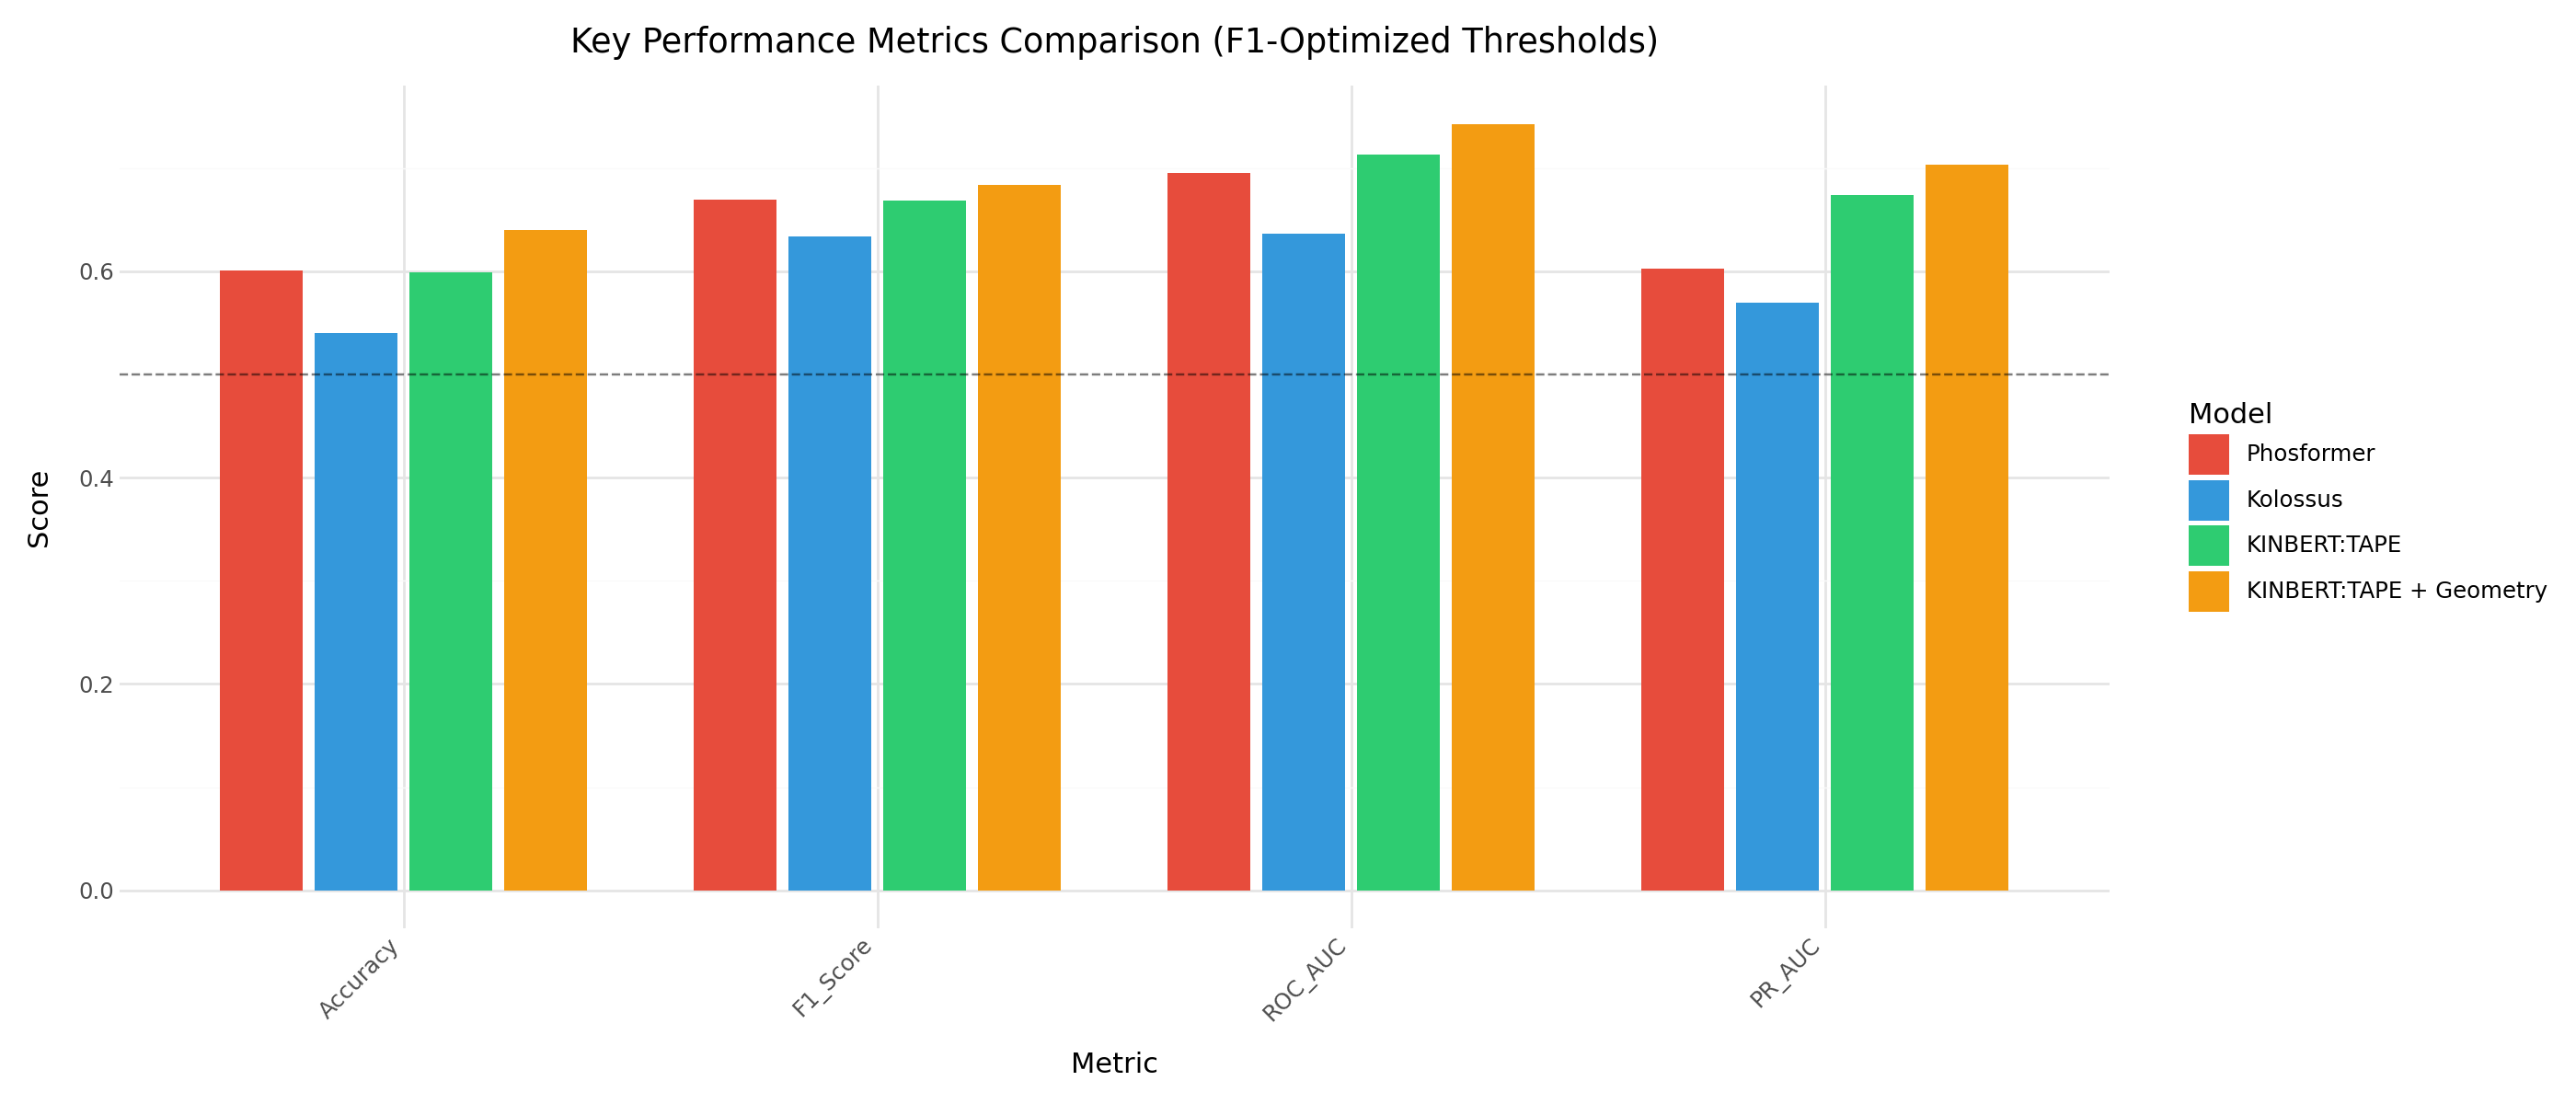

In [21]:
p2

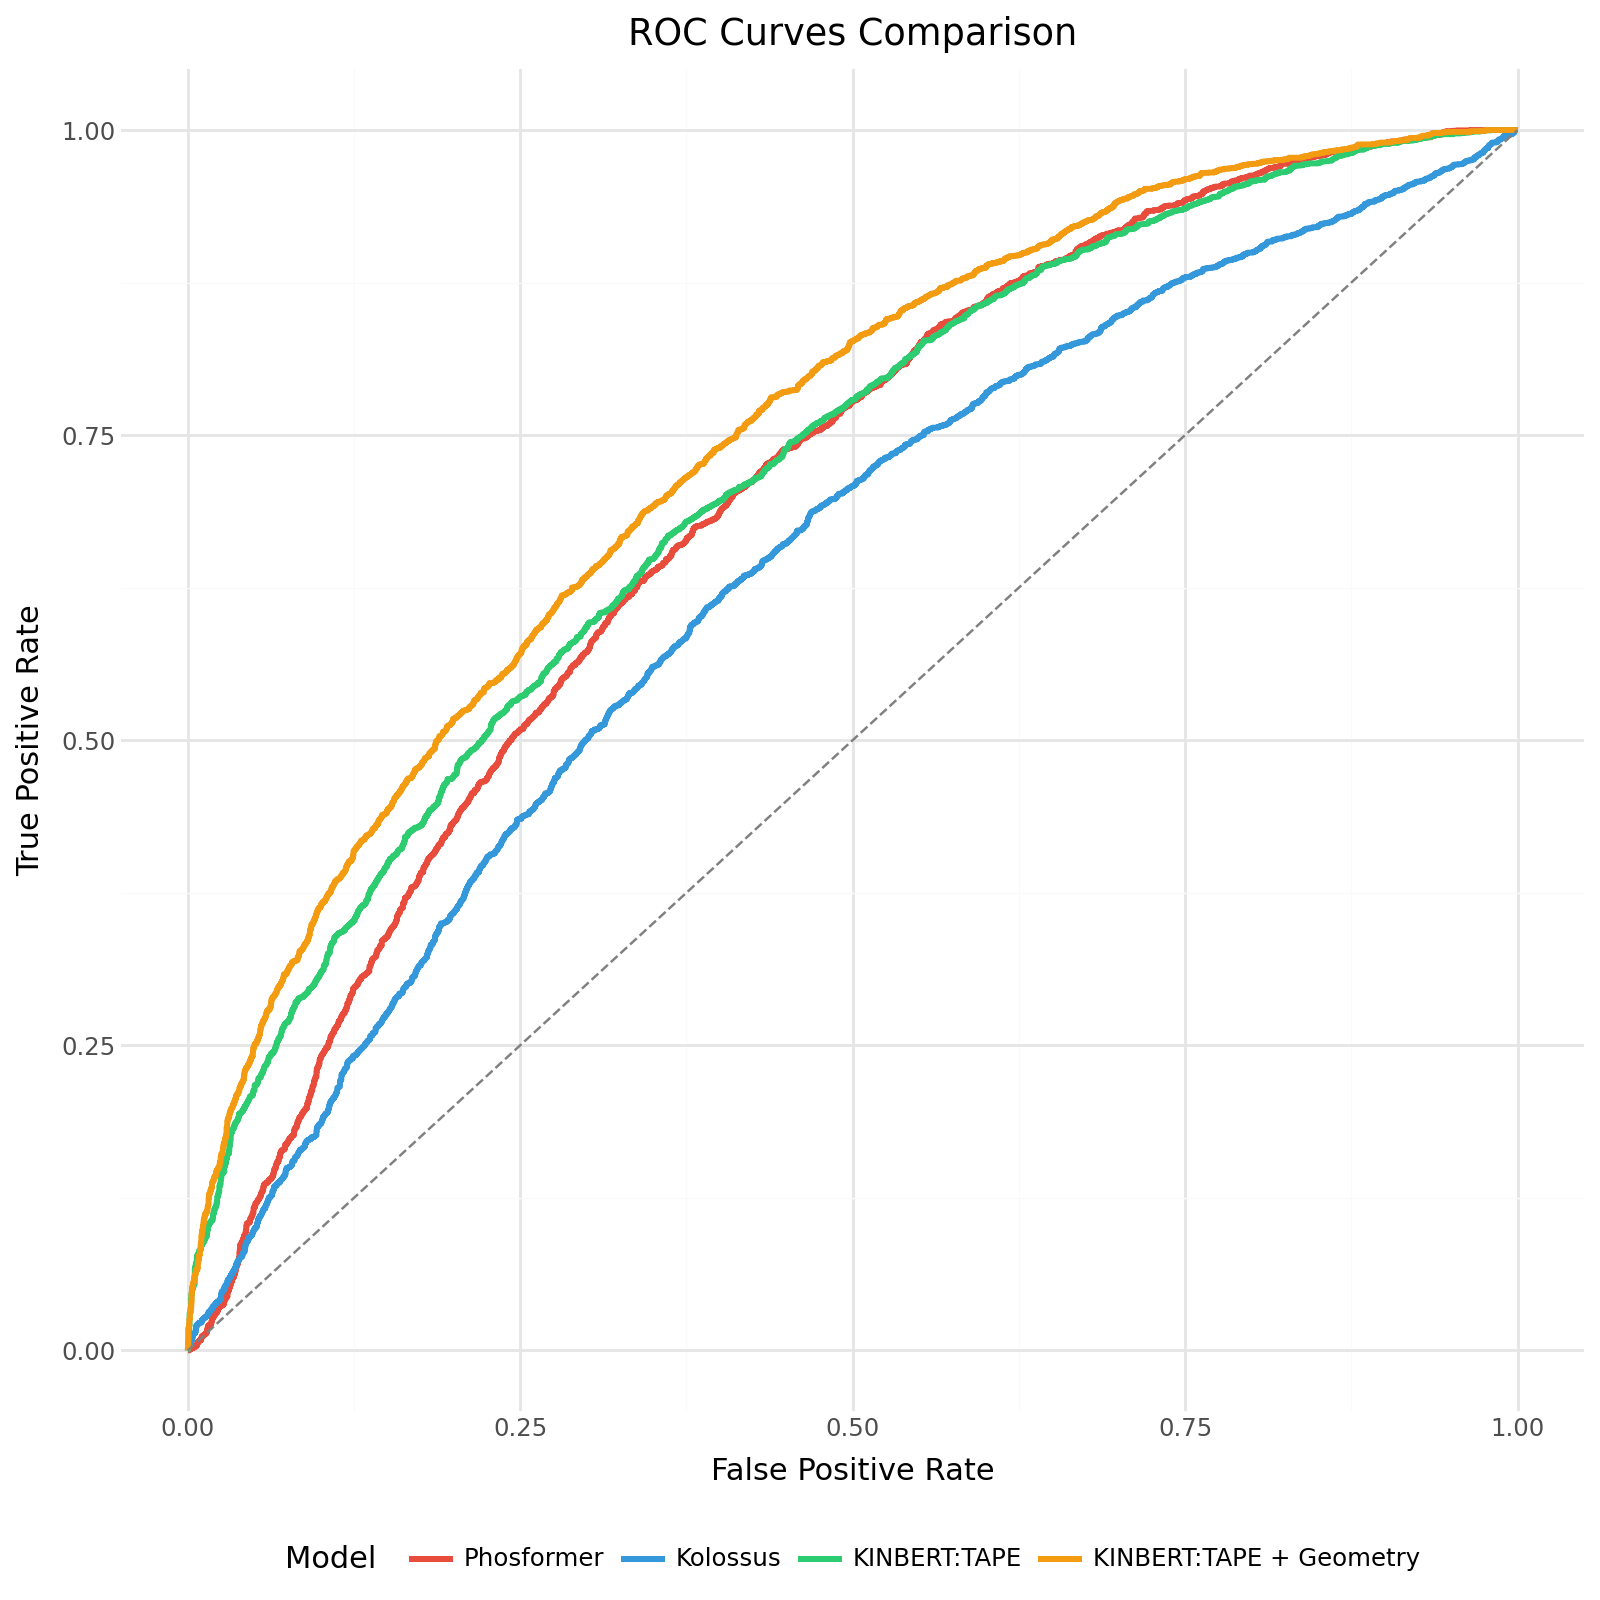

In [22]:
p4

In [8]:
benchmark_id = 'eval_yeast'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')

## Evaluation on KSI screening dataset

In [74]:
pairs_yeast = pd.read_csv('/ksi_ml/data/pairs_aug_ksi.csv').iloc[:,1:].drop_duplicates()
pairs_yeast = pairs_yeast.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

phosphomer_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_ksi.csv').iloc[:,1:]
phosphomer_yeast = phosphomer_yeast.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_yeast.columns = ['kinase_seq','substrate_seq','probs']

kolossus_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_ksi.csv').iloc[:,1:]
kolossus_yeast = pd.merge(kolossus_yeast,pairs_yeast,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_yeast.columns = ['kinase_seq','substrate_seq','probs']

esm_db_lysate_yeast = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__ksi__a543af984148.pkl').drop_duplicates()
tape_db_lysate_yeast = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2__ksi__1b97f9a11dd9.pkl').drop_duplicates()

esm_db_lysate_yeast_early_loss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__ksi__a897476626a9.pkl').drop_duplicates()
tape_db_lysate_yeast_early_loss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_early_loss__ksi__f6ce2993434c.pkl').drop_duplicates()

tape_struct_db_lysate_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/tape_struct_3epoch/bert_struct_eval_pairs_ksi.csv').iloc[:,1:].drop_duplicates()
tape_struct_db_lysate_yeast = tape_struct_db_lysate_yeast.loc[:,['kinase_seq','substrate_seq','prob_positive']].drop_duplicates()
tape_struct_db_lysate_yeast.columns = ['kinase_seq','substrate_seq','probs']

# pairs_yeast should only be mutated after all the above code
pairs_yeast = pairs_yeast.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_yeast.columns = ['kinase_seq', 'substrate_seq', 'label']

In [75]:
pairs_pred = pairs_yeast
prediction_dfs = {
    'Phosformer': phosphomer_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate': esm_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate-EarlyLoss': esm_db_lysate_yeast_early_loss.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'TAPE_DB_Lysate-EarlyLoss': tape_db_lysate_yeast_early_loss.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE + Geometry':tape_struct_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

In [76]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  # threshold_mode='fixed',
                                                  #  fixed_threshold=0.5,
                                                   bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC']
                                                  )

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE + Geometry']
Threshold mode: optimal

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (10064, 3)

Initial shapes:
  Phosformer: (10045, 3)
  Kolossus: (10045, 3)
  KINBERT:TAPE: (10045, 3)
  KINBERT:TAPE + Geometry: (10045, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (10064, 4)
  Kolossus: aligned shape = (10064, 4)
  KINBERT:TAPE: aligned shape = (10064, 4)
  KINBERT:TAPE + Geometry: aligned shape = (10064, 4)

✓ All dataframes aligned to length: 10064

[Step 2.5] Finding optimal F1-maximizing thresholds...
  Phosformer:
    Optimal threshold: 0.0196
    Max F1 score: 0.8466
  Kolossus:
    Optimal threshold: 0.0000
    Max F1 score: 0.8465
  KINBERT:TAPE:
    Optimal threshold: 0.0003
    Max F1 score: 0.8701
  KINBERT:TAPE + Geometry:
    Optimal threshold: 0.0246
    Max F1 scor

In [77]:
metrics_df.loc[:,['Model','ROC_AUC','PR_AUC']]

,Model,ROC_AUC,PR_AUC
0,Phosformer,0.494744,0.759362
1,Kolossus,0.400984,0.691548
2,KINBERT:TAPE,0.758473,0.879821
3,KINBERT:TAPE + Geometry,0.724861,0.852653


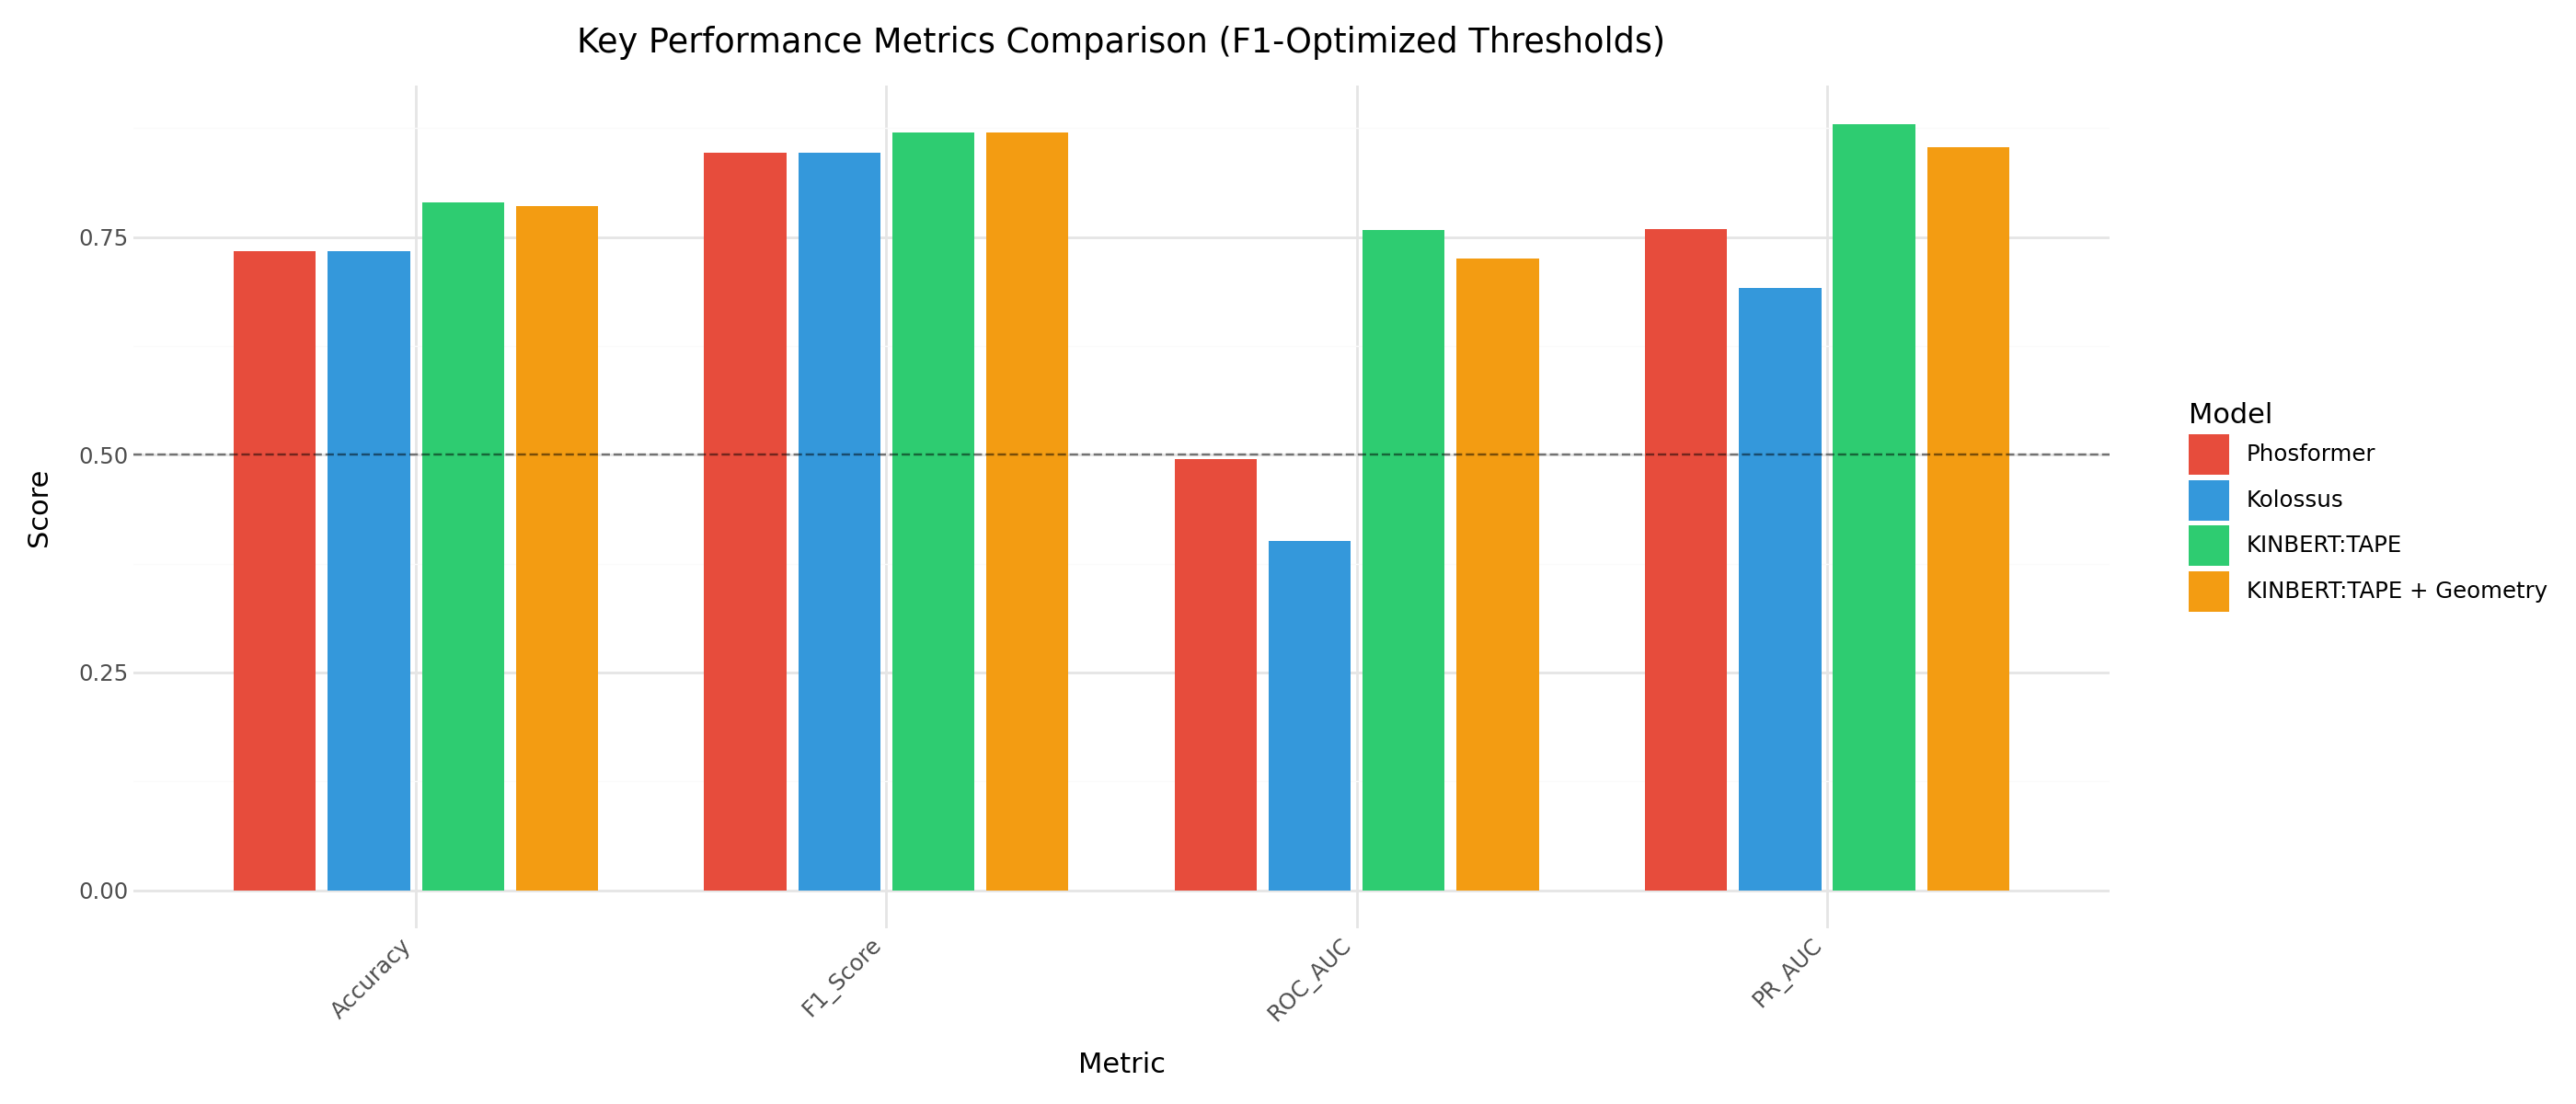

In [78]:
p2

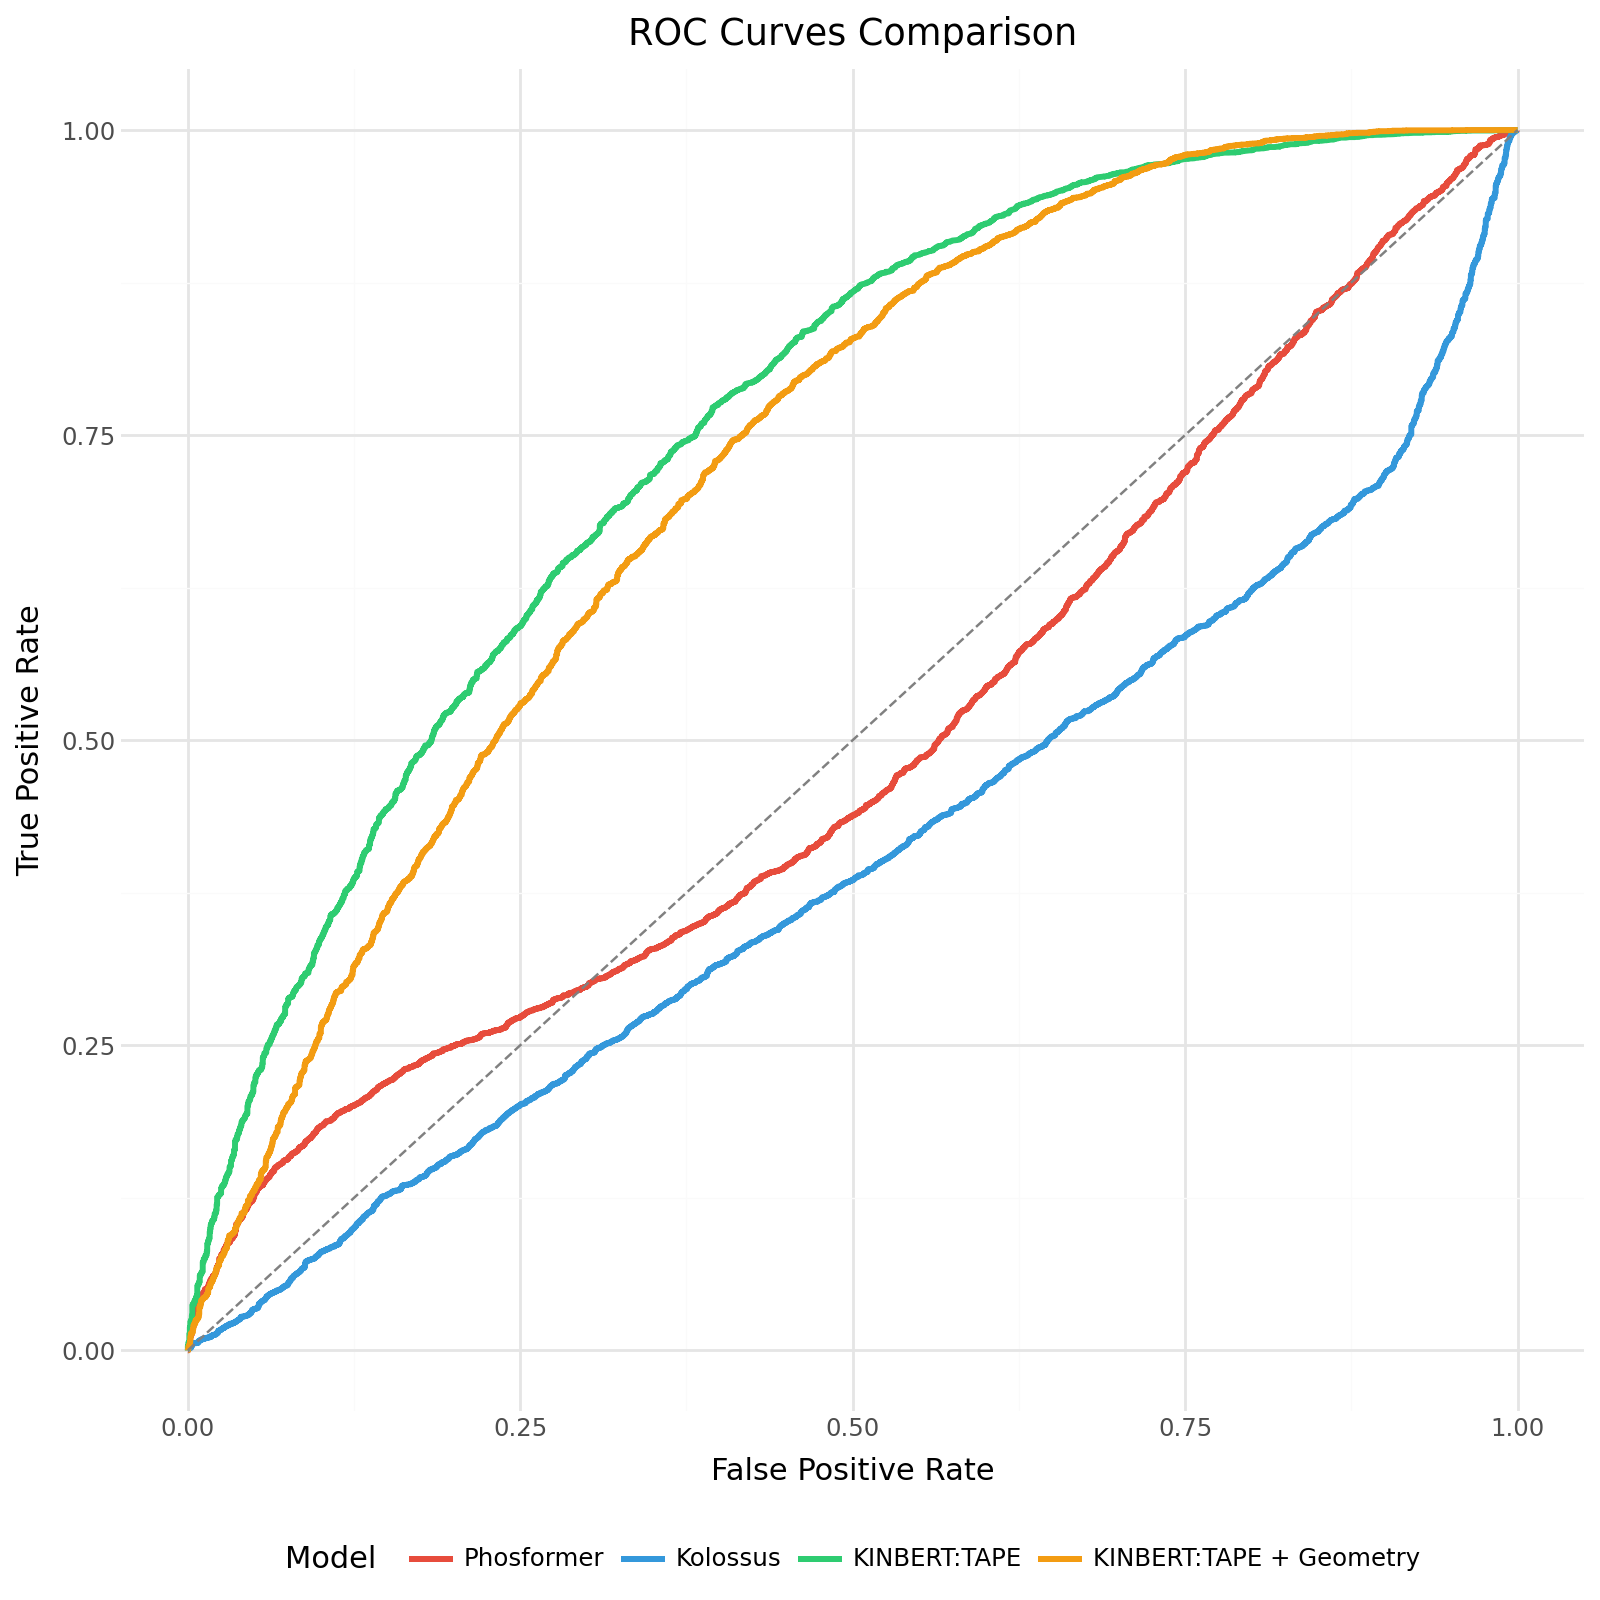

In [79]:
p4

In [26]:
benchmark_id = 'eval_ksi'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')